In [1]:
import pandas as pd

cars = pd.read_csv("cars.csv")   
print(cars.shape)               
cars.head()

(200, 4)


,car_age,km_thousands,engine_cc,price_lakh
0,13,146,1300,14.2
1,4,36,1800,44.2
2,1,1,1800,49.6
3,4,44,1800,50.6
4,6,78,1300,32.2


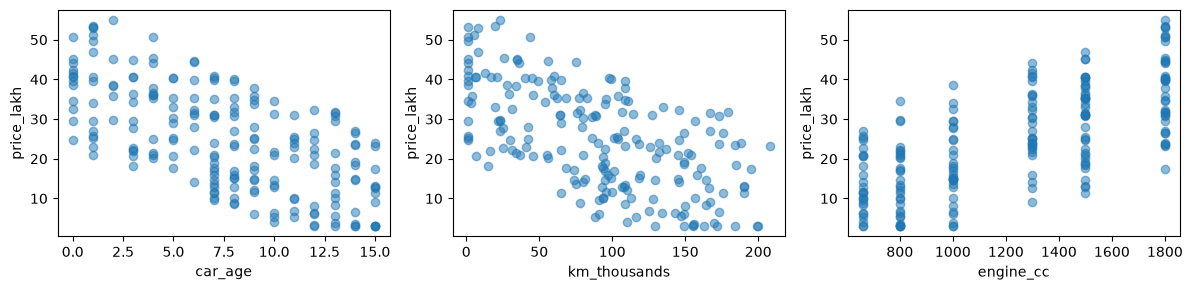

In [5]:
import matplotlib.pyplot as plt

features = ["car_age", "km_thousands", "engine_cc"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.0))
for ax, col in zip(axes, features):
    ax.scatter(cars[col], cars["price_lakh"], alpha=0.5)
    ax.set_xlabel(col)
    ax.set_ylabel("price_lakh")
plt.tight_layout()
plt.show()

In [6]:
cars.corr()["price_lakh"].round(2)

car_age        -0.65
km_thousands   -0.63
engine_cc       0.70
price_lakh      1.00
Name: price_lakh, dtype: float64

In [8]:
X = cars[features]
y = cars["price_lakh"]

print("X:", X.shape)
print("Y:", y.shape)
X.head(3)

X: (200, 3)
Y: (200,)


,car_age,km_thousands,engine_cc
0,13,146,1300
1,4,36,1800
2,1,1,1800


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", len(X_train), "cars")
print("Test: ", len(X_test), "cars")

Train: 160 cars
Test:  40 cars


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=5),
}

for name, m in models.items():
    m.fit(X_train, y_train)                                   # same 3 steps for every model:
    err = mean_absolute_error(y_test, m.predict(X_test))      # create → fit → predict
    print(name, "→ average error:", round(err, 1), "lakh")

Linear Regression → average error: 2.0 lakh
Decision Tree → average error: 3.6 lakh
KNN → average error: 2.9 lakh


In [11]:
line_model = LinearRegression()
line_model.fit(X_train[["engine_cc"]], y_train)

b1 = line_model.coef_[0]
b0 = line_model.intercept_
print("slope (β1):", round(b1, 2))
print("intercept (β0):", round(b0, 2))
print("Rule: price =", round(b0, 1), "+", round(b1, 2), "× size")

slope (β1): 0.02
intercept (β0): -2.75
Rule: price = -2.8 + 0.02 × size
